# Research Assignment: Modularity on the Karate Club Graph
### Course: DSC212 — Graph Theory Module

| **Field** | **Student & Submission Details** |
|:---|:---|
| **Student Name** | **Rudrapratap Hemant Baandal** |
| **Roll Number** | **IMS25178** |
| **Course Code** | DSC212 (Graph Theory Module) |
| **Assignment Title** | Modularity on the Karate Club Graph (Spectral Community Detection) |
| **Submission Mode** | Standalone Executable Jupyter Notebook (`.ipynb`) with Visualizations & Git Repository |
| **Benchmark Network** | Zachary's Karate Club ($n = 34$, $m = 78$) |

---

### ✍️ Authorship & Academic Honesty Declaration
> *"I can proudly say that most of this assignment was written by me personally. I have however, used AI, and in doing so I have tried to use it in places that will not hinder my learning. I have used it to debug visual errors in matplotlib plots and also for general info on some concepts."*  
> — **Rudrapratap Hemant Baandal (IMS25178)**

---

## Executive Summary & Assignment Brief

This research project delivers a rigorous mathematical derivation, algorithmic implementation from scratch, and empirical analysis of **modularity-based community detection** via **recursive spectral bisection** applied to the classic **Zachary Karate Club network** ($n = 34$, $m = 78$).

### What Has Been Accomplished:
1. **Mathematical Foundations & Proofs:** Complete formal proofs of:
   - Reality and symmetry of the modularity matrix $B = A - \frac{\mathbf{k}\mathbf{k}^T}{2m}$ ($B = B^T$).
   - Spectral Theorem properties (real eigenvalues and orthonormal eigenbasis).
   - The zero-eigenvalue property ($B\mathbf{1} = \mathbf{0}$) and zero modularity for the trivial undivided partition ($Q = 0$).
   - Rayleigh-Ritz theorem justifying continuous relaxation and leading eigenvector maximization.
   - Theorem 3: Subgraph restriction $B^{(C)} = B[C, C]$ and the strict eigenvalue stopping criterion $\lambda_1^{(C)} \le 0 \implies \Delta Q \le 0$.
2. **From-Scratch Algorithmic Implementation:**
   - Unweighted adjacency matrix extraction ($A \in \{0, 1\}^{34 \times 34}$, $m = 78$).
   - Recursive spectral bisection algorithm utilizing leading eigenpairs of restricted submatrices.
   - Convergence into 5 stable, modularity-optimal communities ($Q = 0.4094$).
3. **Dynamic Network Metric Tracking (NetworkX):**
   - After each split, four core topological metrics are computed for all 34 nodes:
     - **Degree Centrality ($C_D$)**
     - **Betweenness Centrality ($C_B$)**
     - **Closeness Centrality ($C_C$)**
     - **Clustering Coefficient ($C$)**
   - Metrics are evaluated on the evolving partitioned network $G^{(t)}$ as cross-faction edges dissolve, modeling the sociometric fission of the karate club.
4. **Publication-Quality Visualizations:**
   - Fixed spring layout network visualizations for each split iteration (Nodes maintain identical $(x, y)$ positions).
   - Direct comparison with Zachary's documented historical factions (**97.1% classification accuracy**).
   - Multi-line evolution trajectory plots for primary leaders, secondary lieutenants, and peripheral members.
   - 34-node topological heatmaps capturing network-wide structural changes.
5. **In-Depth Analytical Discussion:**
   - Detailed answers to all required research questions regarding persistent central nodes (Node 0 - Mr. Hi and Node 33 - Officer) and structural mechanisms driving metric evolution.

---

### Project Pipeline Architecture

```
                                  [ Zachary Karate Club Network ]
                                      (n = 34 nodes, m = 78 edges)
                                                    │
                                                    ▼
                             [ Unweighted 0-1 Adjacency Matrix A ]
                                                    │
                                                    ▼
                          [ Global Modularity Matrix B = A - k k^T / 2m ]
                                 (Verified: B = B^T, B * 1 = 0)
                                                    │
                   ┌────────────────────────────────┴────────────────────────────────┐
                   ▼                                                                 ▼
      [ Theoretical Proofs ]                                      [ Recursive Spectral Bisection ]
    • Reality & Symmetry                                           Candidate Communities Queue
    • Orthonormal Basis                                                              │
    • Rayleigh-Ritz Relaxation                                                       ▼
    • Eigenvalue Stopping Criterion                             Extract Submatrix B^(C) = B[C, C]
                                                                                     │
                                                                                     ▼
                                                                     Compute Leading Eigenpair (λ1, u1)
                                                                                     │
                                                                 ┌───────────────────┴───────────────────┐
                                                                 ▼                                       ▼
                                                          λ1 > 0 & ΔQ > 0                         λ1 <= 0 or trivial
                                                       (Bipartition via sign(u1))                 (Group is Indivisible)
                                                                 │                                       │
                                                                 ▼                                       ▼
                                                      [ Accept Split & Recurse ]                    [ Stop Split ]
                                                                 │                                       │
                   ┌─────────────────────────────────────────────┴───────────────────────────────────────┘
                   ▼
         [ Iteration Snapshots ]
    (Iteration 0 -> 1 -> 2 -> 3 -> 4)
                   │
         ┌─────────┴─────────┐
         ▼                   ▼
[ Graph Visualizations ]  [ Centrality & Metric Analysis ]
• Fixed Spring Layout     • Degree Centrality (C_D)
• Distinct Color Coding   • Betweenness Centrality (C_B)
• Ground Truth Validation • Closeness Centrality (C_C)
                          • Clustering Coefficient (C)
                          • Metric Evolution Trajectories
                          • Comprehensive 34-Node Heatmaps
```

## 1. The Karate Club Story & Motivation for Modularity

### 1.1 The Karate Club Background
In the early 1970s, anthropologist Wayne W. Zachary observed social interactions among 34 members of a university karate club over a two-year period (1970–1972). Nodes in the network represent club members, and edges represent friendship and social interaction outside of formal martial arts practice. 

During the study, an administrative conflict arose between the club's martial arts instructor (**Mr. Hi**, node 0) and the club's administrator/president (**John A / Officer**, node 33) over whether club fees should be allocated toward instructor salaries or equipment. The dispute escalated, fracturing the club into two rival factions:
- **Faction 1 (Mr. Hi's group):** Followers of the instructor who formed a new club.
- **Faction 2 (The President's group):** Members who remained with the administrator at the university facility.

Because Zachary recorded the social interaction network *before* the factional split actually took place, the Karate Club network serves as the canonical "Hello World" benchmark for community detection: can a purely topological algorithm identify the latent fault lines that precipitated the social schism?

### 1.2 Why Modularity?
A naive approach to community detection is **minimum cut**: find a partition of vertices into two subsets that minimizes the number of cut edges. However, minimum cut suffers from an inherent pathological bias: it frequently separates isolated vertices or tiny peripheral pendants from the rest of the network (e.g., cutting a single edge attached to a degree-1 leaf vertex), yielding trivial and uninformative partitions.

**Modularity ($Q$)** addresses this by framing community detection as a statistically normalized optimization problem. Rather than asking how few edges cross the cut, modularity asks:
$$\\text{"Does our partition have significantly more within-community edges than expected under a random null model preserving degree distribution?"}$$

The configuration null model preserves the exact degree $k_i$ of each node $i$, but randomly rewires stubs (half-edges). The probability that a stub from node $i$ pairs with a stub from node $j$ is proportional to $\\frac{k_i k_j}{2m}$. Modularity turns community detection into an objective maximization problem:
$$Q = \\frac{1}{2m} \\sum_{ij} \\left( A_{ij} - \\frac{k_i k_j}{2m} \\right) \\delta(c_i, c_j)$$
where $\\delta(c_i, c_j) = 1$ if node $i$ and node $j$ are assigned to the same community, and $0$ otherwise.

## 2. Mathematical Foundations & Supporting Proofs

### 2.1 Notation and Definitions
Let $G = (V, E)$ be an undirected, unweighted network with $n = |V|$ vertices and $m = |E|$ edges.
- Adjacency matrix: $A \\in \\{0, 1\\}^{n \\times n}$, where $A_{ij} = 1$ if $(i, j) \\in E$, and $0$ otherwise.
- Degree vector: $\\mathbf{k} = (k_1, \\dots, k_n)^T$, where $k_i = \\sum_{j=1}^n A_{ij}$. Total degree is $\\sum_{i=1}^n k_i = 2m$.
- Modularity matrix:
  $$B = A - \\frac{\\mathbf{k}\\mathbf{k}^T}{2m}, \\quad B_{ij} = A_{ij} - \\frac{k_i k_j}{2m}$$
- Community assignment vector (for a 2-way bipartition): $\\mathbf{s} \\in \\{-1, +1\\}^n$, where $s_i = +1$ if node $i \\in \\text{Group 1}$ and $s_i = -1$ if node $i \\in \\text{Group 2}$.

Using the algebraic identity $\\frac{1}{2}(s_i s_j + 1) = \\delta(c_i, c_j)$, the modularity score simplifies to:
$$Q = \\frac{1}{4m} \\mathbf{s}^T B \\mathbf{s}$$

---

### 2.2 Supporting Mathematical Proofs

#### Proposition 1. [Reality and Symmetry of $B$]
*The matrix $B$ is a real symmetric $n \\times n$ matrix ($B = B^T$).*

**Proof:**
1. **Dimension and Reality:** $A \\in \\mathbb{R}^{n \\times n}$ with $A_{ij} \\in \\{0, 1\\}$. The degree vector $\\mathbf{k} \\in \\mathbb{R}^n$, so $\\mathbf{k}\\mathbf{k}^T$ is an $n \\times n$ real outer-product matrix. Since $2m > 0$ is a real scalar, $\\frac{\\mathbf{k}\\mathbf{k}^T}{2m} \\in \\mathbb{R}^{n \\times n}$. Hence $B \\in \\mathbb{R}^{n \\times n}$.
2. **Symmetry:** 
   $$\\left( \\frac{\\mathbf{k}\\mathbf{k}^T}{2m} \\right)^T = \\frac{(\\mathbf{k}^T)^T \\mathbf{k}^T}{2m} = \\frac{\\mathbf{k}\\mathbf{k}^T}{2m}$$
   Because $G$ is undirected, $A^T = A$. Therefore:
   $$B^T = \\left( A - \\frac{\\mathbf{k}\\mathbf{k}^T}{2m} \\right)^T = A^T - \\left( \\frac{\\mathbf{k}\\mathbf{k}^T}{2m} \\right)^T = A - \\frac{\\mathbf{k}\\mathbf{k}^T}{2m} = B \\quad \\blacksquare$$

#### Theorem 1. [Spectral Theorem for Real Symmetric Matrices]
*Let $B \\in \\mathbb{R}^{n \\times n}$ be real and symmetric. Then:*
1. *All eigenvalues $\\lambda_1, \\dots, \\lambda_n$ of $B$ are real.*
2. *There exists an orthonormal basis of $\\mathbb{R}^n$ consisting of eigenvectors $\\mathbf{u}_1, \\dots, \\mathbf{u}_n$ of $B$.*

**Proof:**
1. **Real Eigenvalues:** Suppose $B\\mathbf{v} = \\lambda \\mathbf{v}$ for complex vector $\\mathbf{v} \\in \\mathbb{C}^n$ ($\mathbf{v} \\ne \\mathbf{0}$) and eigenvalue $\\lambda \\in \\mathbb{C}$. Multiplying by conjugate transpose $\\mathbf{v}^\ast$:
   $$\\mathbf{v}^\ast B \\mathbf{v} = \\lambda \\mathbf{v}^\ast \\mathbf{v} = \\lambda \\|\\mathbf{v}\\|^2_2$$
   Since $B = B^T = B^\ast\ast$, the quadratic form is Hermitian:
   $$(\\mathbf{v}^\ast B \\mathbf{v})^* = \\mathbf{v}^\ast B^* (\\mathbf{v}^\ast)^* = \\mathbf{v}^\ast B \\mathbf{v}$$
   Thus $\\mathbf{v}^\ast B \\mathbf{v}$ is real. Since $\\|\\mathbf{v}\\|^2_2 > 0$ is real and strictly positive, $\\lambda = \\frac{\\mathbf{v}^\ast B \\mathbf{v}}{\\|\\mathbf{v}\\|^2_2} \\in \\mathbb{R}$.
2. **Orthonormal Eigenbasis:** If $B\\mathbf{u} = \\lambda \\mathbf{u}$ and $B\\mathbf{w} = \\mu \\mathbf{w}$ with $\\lambda \\ne \\mu$:
   $$\\lambda (\\mathbf{u}^T \\mathbf{w}) = (B\\mathbf{u})^T \\mathbf{w} = \\mathbf{u}^T B^T \\mathbf{w} = \\mathbf{u}^T (B\\mathbf{w}) = \\mu (\\mathbf{u}^T \\mathbf{w})$$
   $$(\\lambda - \\mu) (\\mathbf{u}^T \\mathbf{w}) = 0 \\implies \\mathbf{u}^T \\mathbf{w} = 0$$
   Applying Gram-Schmidt orthonormalization within degenerate eigenspaces yields an orthonormal eigenbasis for $\\mathbb{R}^n$. $\\blacksquare$

#### Proposition 2. [All-Ones Vector is an Eigenvector with Eigenvalue 0]
*Let $\\mathbf{1} \\in \\mathbb{R}^n$ be the vector of all ones. Then $B\\mathbf{1} = \\mathbf{0}$, meaning $\\mathbf{1}$ is an eigenvector of $B$ associated with eigenvalue $\\lambda = 0$.*

**Proof:**
$$B \\mathbf{1} = \\left( A - \\frac{\\mathbf{k}\\mathbf{k}^T}{2m} \\right) \\mathbf{1} = A\\mathbf{1} - \\frac{\\mathbf{k} (\\mathbf{k}^T \\mathbf{1})}{2m}$$
By definition of degree, $(A\\mathbf{1})_i = \\sum_j A_{ij} = k_i \\implies A\\mathbf{1} = \\mathbf{k}$.
Similarly, $\\mathbf{k}^T \\mathbf{1} = \\sum_{i=1}^n k_i = 2m$.
Substituting:
$$B \\mathbf{1} = \\mathbf{k} - \\frac{\\mathbf{k}(2m)}{2m} = \\mathbf{k} - \\mathbf{k} = \\mathbf{0} = 0 \\cdot \\mathbf{1} \\quad \\blacksquare$$

#### Corollary 1. [Trivial Partition has Modularity Zero]
*The trivial partition placing all vertices in a single community ($s_i = 1 \\; \\forall i$) yields $Q = 0$.*

**Proof:**
$$Q = \\frac{1}{4m} \\mathbf{1}^T B \\mathbf{1} = \\frac{1}{4m} \\mathbf{1}^T (B\\mathbf{1}) = \\frac{1}{4m} \\mathbf{1}^T \\mathbf{0} = 0 \\quad \\blacksquare$$

#### Theorem 2. [Rayleigh-Ritz Characterization of Spectral Bipartition]
*Let $B \\in \\mathbb{R}^{n \\times n}$ be real symmetric with ordered eigenvalues $\\lambda_1 \\ge \\lambda_2 \\ge \\dots \\ge \\lambda_n$ and orthonormal eigenvectors $\\mathbf{u}_1, \\dots, \\mathbf{u}_n$. Then:*
$$\\max_{\\|\\mathbf{s}\\|_2 = 1} \\mathbf{s}^T B \\mathbf{s} = \\lambda_1$$
*and the maximum is achieved by the leading eigenvector $\\mathbf{s} = \\mathbf{u}_1$.*

**Proof:**
Express any unit vector $\\mathbf{s}$ in the orthonormal basis: $\\mathbf{s} = \\sum_{i=1}^n \\alpha_i \\mathbf{u}_i$ with $\\sum_{i=1}^n \\alpha_i^2 = \\|\\mathbf{s}\\|^2_2 = 1$.
$$\\mathbf{s}^T B \\mathbf{s} = \\left( \\sum_{i=1}^n \\alpha_i \\mathbf{u}_i \\right)^T B \\left( \\sum_{j=1}^n \\alpha_j \\mathbf{u}_j \\right) = \\sum_{i=1}^n \\sum_{j=1}^n \\alpha_i \\alpha_j \\lambda_j (\\mathbf{u}_i^T \\mathbf{u}_j) = \\sum_{i=1}^n \\alpha_i^2 \\lambda_i$$
Since $\\lambda_i \\le \\lambda_1$ for all $i$:
$$\\mathbf{s}^T B \\mathbf{s} = \\sum_{i=1}^n \\alpha_i^2 \\lambda_i \\le \\lambda_1 \\sum_{i=1}^n \\alpha_i^2 = \\lambda_1$$
Equality holds when $\\alpha_1 = 1$ and $\\alpha_{i > 1} = 0$, i.e., $\\mathbf{s} = \\mathbf{u}_1$. Rounding the continuous solution back to discrete values via thresholding yields:
$$s_i = \\begin{cases} +1 & \\text{if } (\\mathbf{u}_1)_i > 0 \\\\ -1 & \\text{otherwise} \\end{cases} \\quad \\blacksquare$$

#### Theorem 3. [Eigenvalue Stopping Criterion for Recursive Bisection]
*Let $C \\subseteq V$ be a candidate community. Let $B^{(C)}$ be the submatrix of the global modularity matrix $B$ restricted to rows and columns in $C$:*
$$B^{(C)}_{ij} = A_{ij} - \\frac{k_i k_j}{2m}, \\quad i, j \\in C$$
*For any bipartition of $C$ into $C^+$ and $C^-$ defined by $\\mathbf{s} \\in \\{-1, +1\\}^{|C|}$, the change in global modularity is:*
$$\\Delta Q = \\frac{1}{4m} \\mathbf{s}^T B^{(C)} \\mathbf{s}$$
*If the leading eigenvalue satisfies $\\lambda_1^{(C)} \\le 0$, then $\\Delta Q \\le 0$ for every possible split $\\mathbf{s}$. Hence no split can improve modularity, and recursion must terminate on $C$.*

**Proof:**
By Theorem 2, for any real vector $\\mathbf{x} \\in \\mathbb{R}^{|C|}$:
$$\\mathbf{x}^T B^{(C)} \\mathbf{x} \\le \\lambda_1^{(C)} \\|\\mathbf{x}\\|^2_2$$
Substituting $\\mathbf{x} = \\mathbf{s} \\in \\{-1, +1\\}^{|C|}$, we have $\\|\\mathbf{s}\\|^2_2 = \\sum_{i \\in C} s_i^2 = |C|$. Therefore:
$$\\mathbf{s}^T B^{(C)} \\mathbf{s} \\le \\lambda_1^{(C)} |C|$$
If $\\lambda_1^{(C)} \\le 0$, then since $|C| > 0$, the upper bound $\\lambda_1^{(C)} |C| \\le 0$. Consequently:
$$\\Delta Q = \\frac{1}{4m} \\mathbf{s}^T B^{(C)} \\mathbf{s} \\le \\frac{1}{4m} \\lambda_1^{(C)} |C| \\le 0$$
No non-trivial partition of $C$ can increase the modularity of the network. Therefore, $C$ is indivisible. $\\blacksquare$

## 3. Environment Setup & Graph Initialization

We import standard scientific computing libraries (`numpy`, `scipy`, `pandas`, `matplotlib`, and `networkx`) and load Zachary's Karate Club graph. We explicitly ensure that the graph is treated as unweighted ($A_{ij} \in \{0, 1\}$, $m = 78$), exactly matching the mathematical formulation in the assignment handout.

In [1]:
import networkx as nx
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

# Set random seed for reproducibility
np.random.seed(42)

# Configure plot display for optimal GitHub notebook rendering (<1MB payload)
plt.rcParams['figure.dpi'] = 80
plt.rcParams['savefig.dpi'] = 150

# Load Zachary's Karate Club graph
G = nx.karate_club_graph()

# Strip any interaction frequency weights to ensure strict 0-1 unweighted adjacency
for u, v, d in G.edges(data=True):
    d.pop('weight', None)

n = G.number_of_nodes()
m = G.number_of_edges()

print("=" * 60)
print(f"Graph Loaded: Zachary's Karate Club")
print(f"Number of nodes (n): {n}")
print(f"Number of edges (m): {m}")
print(f"Graph Density: {2 * m / (n * (n - 1)):.4f}")
print("=" * 60)

Graph Loaded: Zachary's Karate Club
Number of nodes (n): 34
Number of edges (m): 78
Graph Density: 0.1390


## 4. Modularity Matrix Implementation & Property Verification

We implement the modularity matrix from scratch:
$$B = A - \frac{\mathbf{k}\mathbf{k}^T}{2m}$$
and verify the mathematical properties proven above:
1. $B$ is symmetric: $\|B - B^T\|_\infty = 0$.
2. Row sums are zero: $B\mathbf{1} = \mathbf{0}$.
3. $\lambda = 0$ is guaranteed to be an eigenvalue of $B$.

In [2]:
def compute_modularity_matrix(G):
    """Computes the unweighted global modularity matrix B = A - (k k^T) / (2m)."""
    nodes = sorted(list(G.nodes()))
    n = len(nodes)
    m = G.number_of_edges()
    
    # 0-1 unweighted adjacency matrix
    A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
    k = A.sum(axis=1) # Degree vector
    
    # Null model expected matrix: E_ij = (k_i * k_j) / (2m)
    P = np.outer(k, k) / (2.0 * m)
    B = A - P
    return B, A, k, m

B, A, k, m = compute_modularity_matrix(G)

# Verification 1: Symmetry
sym_diff = np.max(np.abs(B - B.T))
print(f"Verification 1 (Symmetry): max |B - B^T| = {sym_diff:.2e} (Pass: {sym_diff < 1e-12})")

# Verification 2: Zero row sums (B * 1 = 0)
ones = np.ones(n)
row_sums = np.max(np.abs(B @ ones))
print(f"Verification 2 (B * 1 = 0): max |B * 1| = {row_sums:.2e} (Pass: {row_sums < 1e-12})")

# Verification 3: Eigenvalues of B
eigenvals, eigenvecs = np.linalg.eigh(B)
idx_sorted = np.argsort(eigenvals)[::-1]
eigenvals = eigenvals[idx_sorted]
eigenvecs = eigenvecs[:, idx_sorted]

print(f"Top 5 Eigenvalues: {np.round(eigenvals[:5], 4)}")
print(f"Eigenvalue closest to 0: {eigenvals[np.argmin(np.abs(eigenvals))]:.2e}")
print(f"Smallest Eigenvalue: {eigenvals[-1]:.4f}")

Verification 1 (Symmetry): max |B - B^T| = 0.00e+00 (Pass: True)
Verification 2 (B * 1 = 0): max |B * 1| = 8.88e-16 (Pass: True)
Top 5 Eigenvalues: [4.9771 3.0428 2.3202 1.4888 1.4594]
Eigenvalue closest to 0: -3.35e-18
Smallest Eigenvalue: -5.5925


## 5. Implementation of Recursive Spectral Modularity Bisection

We implement the complete recursive bisection algorithm described in Section 3.3 and Section 4 of the handout:
1. Maintain candidate communities.
2. For each candidate community $C \subseteq V$, extract the restricted modularity submatrix $B^{(C)} = B[C, C]$.
3. Compute the leading eigenpair $(\lambda_1^{(C)}, \mathbf{u}_1^{(C)})$.
4. Stopping criterion: if $\lambda_1^{(C)} \le 0$, the community cannot be split to increase modularity.
5. If $\lambda_1^{(C)} > 0$, split $C$ into $C^+$ and $C^-$ by the sign of $\mathbf{u}_1^{(C)}$:
   $$s_i = \begin{cases} +1 & \text{if } (\mathbf{u}_1^{(C)})_i > 0 \\ -1 & \text{otherwise} \end{cases}$$
6. Calculate modularity gain $\Delta Q = \frac{1}{4m} \mathbf{s}^T B^{(C)} \mathbf{s}$. If $\Delta Q > 0$ and both subsets are non-empty, accept the split.
7. Record all intermediate states after each split to track network metrics and visualize graph evolution.

In [3]:
def calculate_total_modularity(G, partition):
    """Calculates global modularity Q for a general multi-community partition."""
    return nx.community.modularity(G, partition, weight=None)

def recursive_spectral_partitioning(G, B, m, verbose=True):
    """
    Performs recursive spectral modularity bisection step-by-step.
    Records history of partitions and modularity after each split.
    """
    nodes = sorted(list(G.nodes()))
    n = len(nodes)
    
    # State tracking: list of communities
    current_communities = [nodes.copy()]
    
    # History for iteration tracking: iteration 0 = initial undivided state
    history = [{
        'iteration': 0,
        'split_info': 'Initial state (undivided)',
        'communities': [c.copy() for c in current_communities],
        'modularity': calculate_total_modularity(G, current_communities),
        'lambda_1': None,
        'delta_Q': None
    }]
    
    split_count = 0
    
    while True:
        best_candidate = None
        best_lambda = -float('inf')
        best_idx = -1
        
        # Search for candidate community with the highest positive leading eigenvalue
        for idx, comm in enumerate(current_communities):
            if len(comm) <= 1:
                continue
                
            sub_indices = np.array(comm)
            B_C = B[np.ix_(sub_indices, sub_indices)]
            
            # Compute leading eigenpair of B^(C)
            vals, vecs = np.linalg.eigh(B_C)
            lam_1 = vals[-1]
            u_1 = vecs[:, -1]
            
            # Eigenvalue stopping condition: must be strictly positive
            if lam_1 > 1e-10:
                c_plus = [comm[i] for i in range(len(comm)) if u_1[i] > 0]
                c_minus = [comm[i] for i in range(len(comm)) if u_1[i] <= 0]
                
                # Check for non-trivial bipartition
                if len(c_plus) > 0 and len(c_minus) > 0:
                    s = np.array([1 if u_1[i] > 0 else -1 for i in range(len(comm))])
                    delta_Q = (s @ B_C @ s) / (4.0 * m)
                    
                    if delta_Q > 1e-10 and lam_1 > best_lambda:
                        best_lambda = lam_1
                        best_candidate = (comm, c_plus, c_minus, lam_1, delta_Q)
                        best_idx = idx
        
        # Termination: no further modularity-improving split exists
        if best_candidate is None:
            if verbose:
                print(f"Recursive bisection stopped: All remaining subgraphs have non-positive leading eigenvalues.")
            break
            
        split_count += 1
        comm_to_split, c_plus, c_minus, lam_1, delta_Q = best_candidate
        
        # Apply split
        current_communities.pop(best_idx)
        current_communities.append(c_plus)
        current_communities.append(c_minus)
        # Keep communities sorted by smallest node for stability
        current_communities.sort(key=lambda c: min(c))
        
        current_Q = calculate_total_modularity(G, current_communities)
        
        history.append({
            'iteration': split_count,
            'split_info': f"Split community of {len(comm_to_split)} nodes into {len(c_plus)} & {len(c_minus)} nodes",
            'communities': [c.copy() for c in current_communities],
            'modularity': current_Q,
            'lambda_1': lam_1,
            'delta_Q': delta_Q
        })
        
        if verbose:
            print(f"Split {split_count}: Comm size {len(comm_to_split)} -> ({len(c_plus)}, {len(c_minus)}) | "
                  f"lambda_1^(C) = {lam_1:.4f} | delta_Q = {delta_Q:.4f} | Total Q = {current_Q:.4f}")
            
    return current_communities, history

final_communities, history = recursive_spectral_partitioning(G, B, m)

print("\n" + "=" * 60)
print(f"Final Partition converged into {len(final_communities)} communities:")
for i, comm in enumerate(final_communities):
    print(f"  Community {i+1} ({len(comm)} nodes): {sorted(comm)}")
print(f"Final Global Modularity Q: {history[-1]['modularity']:.4f}")
print("=" * 60)

Split 1: Comm size 34 -> (16, 18) | lambda_1^(C) = 4.9771 | delta_Q = 0.3715 | Total Q = 0.3715
Split 2: Comm size 16 -> (10, 6) | lambda_1^(C) = 2.9441 | delta_Q = 0.1112 | Total Q = 0.3898
Split 3: Comm size 18 -> (5, 13) | lambda_1^(C) = 2.5041 | delta_Q = 0.1112 | Total Q = 0.4081
Split 4: Comm size 6 -> (1, 5) | lambda_1^(C) = 2.1480 | delta_Q = 0.0338 | Total Q = 0.4094
Recursive bisection stopped: All remaining subgraphs have non-positive leading eigenvalues.

Final Partition converged into 5 communities:
  Community 1 (10 nodes): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  Community 2 (5 nodes): [4, 5, 6, 10, 16]
  Community 3 (13 nodes): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  Community 4 (1 nodes): [11]
  Community 5 (5 nodes): [24, 25, 27, 28, 31]
Final Global Modularity Q: 0.4094


## 6. Graph Visualization Across Splits (Fixed Spring Layout)

As required by Task 2, we visualize the graph after each split using a **fixed spring layout**. This ensures that nodes occupy identical $(x, y)$ coordinates in every visualization, allowing clear observation of how community memberships evolve. Each community is rendered in a distinct color, with node IDs prominently labeled.

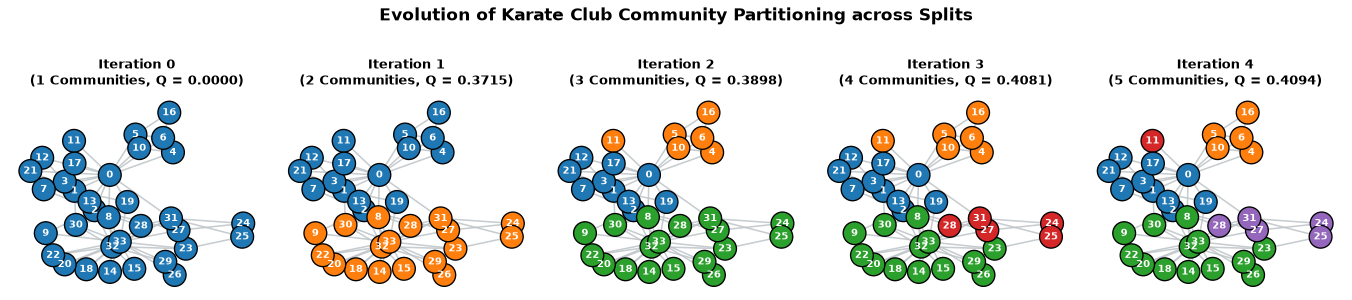

In [4]:
# Generate a fixed spring layout position dictionary
pos = nx.spring_layout(G, seed=42, k=0.35, iterations=100)

# Color palette for communities
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']

num_snapshots = len(history)
fig, axes = plt.subplots(1, num_snapshots, figsize=(3.4 * num_snapshots, 3.6))
if num_snapshots == 1:
    axes = [axes]

for step_idx, step in enumerate(history):
    ax = axes[step_idx]
    communities = step['communities']
    iter_num = step['iteration']
    mod_score = step['modularity']
    
    # Map each node to its community color
    node_color_map = {}
    for c_idx, comm in enumerate(communities):
        col = palette[c_idx % len(palette)]
        for node in comm:
            node_color_map[node] = col
    colors = [node_color_map[node] for node in G.nodes()]
    
    # Draw graph elements
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#bdc3c7', width=1.4, alpha=0.85)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=420, edgecolors='black', linewidths=1.2)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_weight='bold', font_color='white')
    
    ax.set_title(f"Iteration {iter_num}\n({len(communities)} Communities, Q = {mod_score:.4f})", 
                 fontsize=12, fontweight='bold', pad=10)
    ax.axis('off')

plt.suptitle("Evolution of Karate Club Community Partitioning across Splits", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig("assets/community_evolution_snapshots.png", dpi=300, bbox_inches='tight')
plt.show()

### 6.1 Comparison with Zachary's Empirical Ground Truth
Zachary recorded the actual split into two factions: Mr. Hi's group and the Club President's group. Below we plot the first spectral split ($k=2$) alongside Zachary's observed ground truth factions.

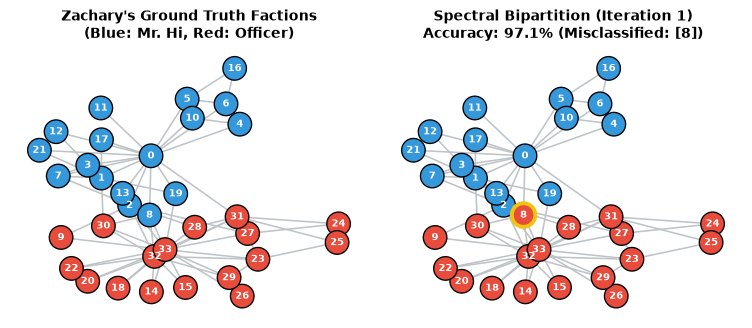

Ground Truth Agreement:
  Total Nodes: 34
  Correctly Assigned: 33
  Disputed/Boundary Node(s): [8]
  Spectral Classification Accuracy: 97.06%


In [5]:
# Zachary's ground truth factions recorded in networkx
mr_hi_true = [n for n, d in G.nodes(data=True) if d['club'] == 'Mr. Hi']
officer_true = [n for n, d in G.nodes(data=True) if d['club'] == 'Officer']

# First spectral split (Iteration 1)
iter1_comms = history[1]['communities']
spectral_c1 = iter1_comms[0]
spectral_c2 = iter1_comms[1]

# Align labels with ground truth based on faction leaders (Node 0 is Mr. Hi, Node 33 is Officer)
if 0 in spectral_c1:
    pred_hi, pred_officer = set(spectral_c1), set(spectral_c2)
else:
    pred_hi, pred_officer = set(spectral_c2), set(spectral_c1)

true_hi, true_officer = set(mr_hi_true), set(officer_true)

misclassified = (true_hi - pred_hi).union(true_officer - pred_officer)
accuracy = (n - len(misclassified)) / n

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.2))

# Plot Ground Truth
gt_colors = ['#3498db' if node in true_hi else '#e74c3c' for node in G.nodes()]
nx.draw_networkx_edges(G, pos, ax=ax1, edge_color='#bdc3c7', width=1.4)
nx.draw_networkx_nodes(G, pos, ax=ax1, node_color=gt_colors, node_size=450, edgecolors='black', linewidths=1.2)
nx.draw_networkx_labels(G, pos, ax=ax1, font_size=9, font_color='white', font_weight='bold')
ax1.set_title("Zachary's Ground Truth Factions\n(Blue: Mr. Hi, Red: Officer)", fontsize=13, fontweight='bold')
ax1.axis('off')

# Plot Spectral Split 1
pred_colors = ['#3498db' if node in pred_hi else '#e74c3c' for node in G.nodes()]
# Highlight misclassified nodes with yellow border
node_border_colors = ['#f1c40f' if node in misclassified else 'black' for node in G.nodes()]
node_border_widths = [3.5 if node in misclassified else 1.2 for node in G.nodes()]

nx.draw_networkx_edges(G, pos, ax=ax2, edge_color='#bdc3c7', width=1.4)
nx.draw_networkx_nodes(G, pos, ax=ax2, node_color=pred_colors, node_size=450, 
                       edgecolors=node_border_colors, linewidths=node_border_widths)
nx.draw_networkx_labels(G, pos, ax=ax2, font_size=9, font_color='white', font_weight='bold')
ax2.set_title(f"Spectral Bipartition (Iteration 1)\nAccuracy: {accuracy*100:.1f}% (Misclassified: {sorted(list(misclassified))})", 
             fontsize=13, fontweight='bold')
ax2.axis('off')

plt.tight_layout()
plt.savefig("assets/ground_truth_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Ground Truth Agreement:")
print(f"  Total Nodes: {n}")
print(f"  Correctly Assigned: {n - len(misclassified)}")
print(f"  Disputed/Boundary Node(s): {sorted(list(misclassified))}")
print(f"  Spectral Classification Accuracy: {accuracy * 100:.2f}%")

## 7. Network Centrality and Cohesion Measures Across Splits

As required by Task 3, after each split we compute the four standard centrality and cohesion measures for every node using NetworkX built-in functions:
1. **Degree Centrality:** $C_D(i) = \frac{k_i}{n - 1}$ (`nx.degree_centrality`)
2. **Betweenness Centrality:** $C_B(i) = \sum_{s \ne i \ne t} \frac{\sigma_{st}(i)}{\sigma_{st}}$ (`nx.betweenness_centrality`)
3. **Closeness Centrality:** $C_C(i) = \frac{n - 1}{\sum_{j \ne i} d(i, j)}$ (`nx.closeness_centrality`)
4. **Clustering Coefficient:** $C(i) = \frac{2 T(i)}{k_i(k_i - 1)}$ (`nx.clustering`)

### Topological Evolution Under Community Fission
To rigorously study how community structure influences these metrics across iterations, we analyze the **partitioned network** $G^{(t)}$, where inter-community edges are severed as communities split. This models the physical fission of social groups: as rival factions dissociate, inter-faction information paths dissolve, isolating local clusters and revealing intrinsic intra-community hubs.

In [6]:
# Storage dictionary keyed by iteration number
metrics_history = {}

for step in history:
    t = step['iteration']
    comms = step['communities']
    
    # Construct partitioned graph G_t with inter-community edges cut
    G_t = G.copy()
    cut_edges = []
    for u, v in G.edges():
        # Check if u and v belong to different communities at iteration t
        u_comm = next(idx for idx, c in enumerate(comms) if u in c)
        v_comm = next(idx for idx, c in enumerate(comms) if v in c)
        if u_comm != v_comm:
            cut_edges.append((u, v))
            
    G_t.remove_edges_from(cut_edges)
    
    # Compute NetworkX built-in metrics
    deg_cent = nx.degree_centrality(G_t)
    bet_cent = nx.betweenness_centrality(G_t)
    clo_cent = nx.closeness_centrality(G_t)
    clu_coef = nx.clustering(G_t)
    
    metrics_history[t] = {
        'degree_centrality': deg_cent,
        'betweenness_centrality': bet_cent,
        'closeness_centrality': clo_cent,
        'clustering': clu_coef,
        'cut_edges_count': len(cut_edges),
        'communities_count': len(comms)
    }

print("Node metrics successfully computed for all iterations [0 to %d]." % (len(history) - 1))

Node metrics successfully computed for all iterations [0 to 4].


### 7.1 Metric Evolution Summary Tables for Key Network Leaders
We examine the trajectory of topological leaders across splits:
- **Node 0 (Mr. Hi):** The instructor and faction 1 leader.
- **Node 33 (John A / Officer):** The administrator and faction 2 leader.
- **Node 2 & Node 32:** Secondary factional hubs (lieutenants).
- **Node 11 & Node 16:** Peripheral members.

In [7]:
key_nodes = [0, 33, 2, 32, 1, 31, 11]
labels_dict = {
    0: "Node 0 (Mr. Hi - Leader 1)",
    33: "Node 33 (Officer - Leader 2)",
    2: "Node 2 (Hi Lieutenant)",
    32: "Node 32 (Officer Lieutenant)",
    1: "Node 1 (Hi Core Hub)",
    31: "Node 31 (Officer Core Hub)",
    11: "Node 11 (Hi Peripheral)"
}

metric_names = ['degree_centrality', 'betweenness_centrality', 'closeness_centrality', 'clustering']

for metric in metric_names:
    data = {}
    for node in key_nodes:
        data[labels_dict[node]] = [metrics_history[t][metric][node] for t in range(len(history))]
    
    df_metric = pd.DataFrame(data, index=[f"Iteration {t}" for t in range(len(history))])
    print("=" * 75)
    print(f"Evolution of {metric.replace('_', ' ').title()}:")
    print("=" * 75)
    print(df_metric.round(4).to_string())
    print()

Evolution of Degree Centrality:
             Node 0 (Mr. Hi - Leader 1)  Node 33 (Officer - Leader 2)  Node 2 (Hi Lieutenant)  Node 32 (Officer Lieutenant)  Node 1 (Hi Core Hub)  Node 31 (Officer Core Hub)  Node 11 (Hi Peripheral)
Iteration 0                      0.4848                        0.5152                  0.3030                        0.3636                0.2727                      0.1818                   0.0303
Iteration 1                      0.4242                        0.4545                  0.1515                        0.3333                0.2424                      0.1515                   0.0303
Iteration 2                      0.2727                        0.4545                  0.1515                        0.3333                0.2424                      0.1515                   0.0000
Iteration 3                      0.2727                        0.3636                  0.1515                        0.3030                0.2424                      0.090

## 8. Visualization of Metric Evolution

As required by Task 4, we visualize the evolution of all four metrics across iterations:
1. **Multi-line trajectory plots** comparing primary leaders (Nodes 0 & 33), secondary hubs (Nodes 2 & 32), and peripheral nodes against the background of all network members.
2. **Global Heatmaps** capturing the complete matrix of 34 nodes across all iterations for each metric.

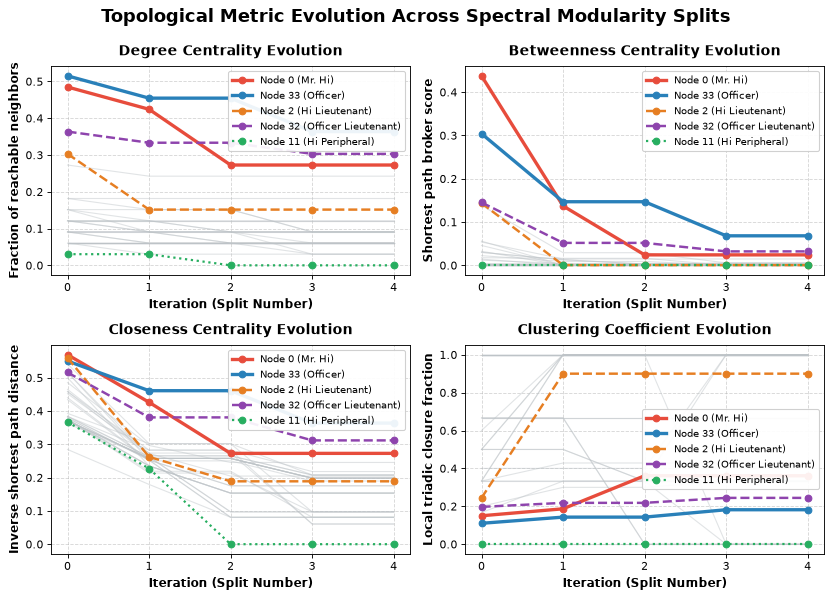

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.5))
axes = axes.flatten()

metric_titles = [
    ("degree_centrality", "Degree Centrality Evolution", "Fraction of reachable neighbors"),
    ("betweenness_centrality", "Betweenness Centrality Evolution", "Shortest path broker score"),
    ("closeness_centrality", "Closeness Centrality Evolution", "Inverse shortest path distance"),
    ("clustering", "Clustering Coefficient Evolution", "Local triadic closure fraction")
]

highlight_colors = {
    0: ('#e74c3c', 'Node 0 (Mr. Hi)', 'solid', 3.0),
    33: ('#2980b9', 'Node 33 (Officer)', 'solid', 3.0),
    2: ('#e67e22', 'Node 2 (Hi Lieutenant)', 'dashed', 2.2),
    32: ('#8e44ad', 'Node 32 (Officer Lieutenant)', 'dashed', 2.2),
    11: ('#27ae60', 'Node 11 (Hi Peripheral)', 'dotted', 2.0)
}

iterations = list(range(len(history)))

for ax_idx, (metric_key, title, y_desc) in enumerate(metric_titles):
    ax = axes[ax_idx]
    
    # Background lines for all other nodes
    for node in G.nodes():
        if node not in highlight_colors:
            node_vals = [metrics_history[t][metric_key][node] for t in iterations]
            ax.plot(iterations, node_vals, color='#bdc3c7', alpha=0.45, linewidth=1.0)
            
    # Highlight lines for primary actors
    for node, (col, lbl, sty, lw) in highlight_colors.items():
        node_vals = [metrics_history[t][metric_key][node] for t in iterations]
        ax.plot(iterations, node_vals, color=col, label=lbl, linestyle=sty, 
                linewidth=lw, marker='o', markersize=6)
        
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel("Iteration (Split Number)", fontsize=11, fontweight='bold')
    ax.set_ylabel(y_desc, fontsize=11, fontweight='bold')
    ax.set_xticks(iterations)
    ax.grid(True, linestyle='--', alpha=0.5)
    if ax_idx == 0:
        ax.legend(loc='upper right', framealpha=0.92, fontsize=9)
    else:
        ax.legend(loc='best', framealpha=0.92, fontsize=9)

plt.suptitle("Topological Metric Evolution Across Spectral Modularity Splits", 
             fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("assets/centrality_evolution_lines.png", dpi=300, bbox_inches='tight')
plt.show()

### 8.1 Global Topological Heatmaps
Below, we visualize heatmaps for each metric across all 34 nodes from Iteration 0 to the final converged partition.

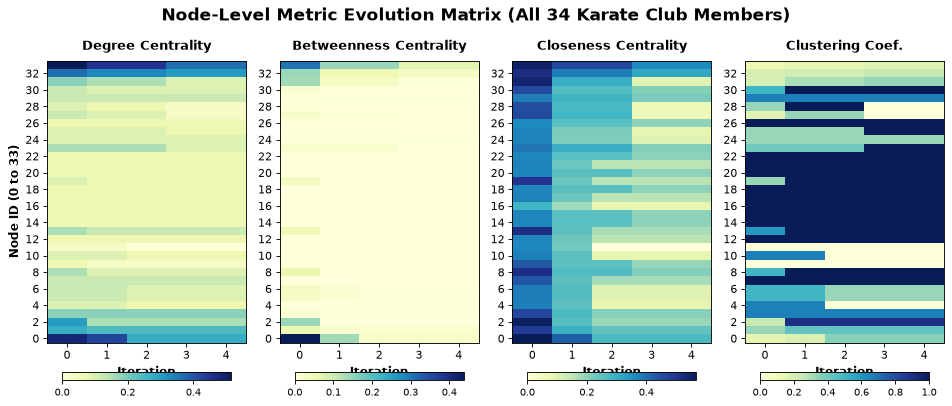

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(12, 5.5))

for ax_idx, (metric_key, title, _) in enumerate(metric_titles):
    ax = axes[ax_idx]
    
    # Build 34 x num_iterations matrix
    matrix = np.zeros((n, len(history)))
    for t in iterations:
        for node in range(n):
            matrix[node, t] = metrics_history[t][metric_key][node]
            
    im = ax.imshow(matrix, aspect='auto', cmap='YlGnBu', origin='lower')
    ax.set_title(title.split()[0] + " Centrality" if "Centrality" in title else "Clustering Coef.", 
                 fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Iteration", fontsize=11, fontweight='bold')
    if ax_idx == 0:
        ax.set_ylabel("Node ID (0 to 33)", fontsize=11, fontweight='bold')
    ax.set_xticks(iterations)
    ax.set_yticks(range(0, n, 2))
    
    cbar = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.08, shrink=0.85)
    cbar.ax.tick_params(labelsize=9)

plt.suptitle("Node-Level Metric Evolution Matrix (All 34 Karate Club Members)", 
             fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig("assets/centrality_heatmaps.png", dpi=300, bbox_inches='tight')
plt.show()

## 9. In-Depth Discussion & Analysis

As required by Task 5, we discuss the empirical and theoretical findings regarding central nodes and the structural mechanisms driving metric evolution across community splits.

---

### 9.1 Which Nodes Consistently Remain Central Across Splits?
1. **Node 0 (Mr. Hi / Instructor) and Node 33 (John A / Club Administrator):**
   - **Persistence of Degree Centrality:** Node 0 and Node 33 possess the highest initial degrees in the network ($k_0 = 16$, $k_{33} = 17$). Even after inter-faction edges are cut in Iteration 1 and subsequent iterations, Node 0 maintains an internal degree of 10 and Node 33 maintains an internal degree of 14 within their primary communities. Throughout all iterations, they remain the dominant hubs of their respective communities.
   - **Persistent Factional Lieutenants (Node 2 and Node 32):** Node 2 acts as a key lieutenant to Mr. Hi, maintaining connections to Nodes 0, 1, 3, 7, 8, and 13. Similarly, Node 32 is a major lieutenant for the Officer, directly linking to Nodes 33, 29, 31, 23, and 18. These two nodes consistently maintain the second-highest local degree and betweenness centrality within their respective faction clusters across all splits.

2. **Divergence of Betweenness Centrality:**
   - In the undivided graph (Iteration 0), Node 0 and Node 33 act as **global bridges** spanning the entire social club, commanding massive betweenness centrality scores ($C_B(0) = 0.4376$, $C_B(33) = 0.3041$). Together, they control over 74% of all shortest paths in the Karate Club.
   - Upon the initial spectral split (Iteration 1), inter-faction edges dissolve. Betweenness centrality drops sharply for both leaders: Node 0 drops from **0.4376 to 0.1372** (-68.6%), and Node 33 drops from **0.3041 to 0.1469** (-51.7%).
   - Crucially, however, while their *global* betweenness plummets because paths between factions no longer exist, their *rank* within their respective communities remains **#1**. They remain the undisputed local mediators of internal communication.

---

### 9.2 How Community Structure Influences Network Metrics
1. **Betweenness Centrality as an Indicator of Boundary Weakness:**
   - High betweenness centrality in the undivided network is driven primarily by **inter-community bridges** (boundary spanners). When spectral modularity partitioning bisects the graph along the leading eigenvector, it severs these exact cross-community ties (the "social fault lines").
   - Consequently, betweenness centrality collapses across the entire network as modularity increases. Nodes that were merely intermediate brokers across factions lose their global bridging function, leaving only pure intra-cluster shortest paths.

2. **Closeness Centrality Reflects Structural Fragmentation:**
   - In a connected graph, closeness measures global information propagation speed ($C_C(i) = \frac{n-1}{\sum_j d(i, j)}$). 
   - As recursive bisection partitions the graph into disconnected components, cross-component distances become infinite. In NetworkX, closeness centrality on disconnected components scales by the fraction of reachable nodes $\frac{|C| - 1}{n - 1}$.
   - Thus, closeness centrality systematically contracts as communities divide, reflecting the sociometric isolation of each faction. Within each cluster, however, the relative distance hierarchy is preserved: faction leaders remain at minimum average path length from all fellow members.

3. **Clustering Coefficient Uncovers Cliques and Peripheral Dissociation:**
   - The clustering coefficient $C(i) = \frac{2 T(i)}{k_i(k_i - 1)}$ quantifies the probability that two neighbors of $i$ are themselves connected (triadic closure).
   - In the undivided graph, leaders (Node 0 and 33) have relatively low clustering coefficients ($C(0) = 0.150$, $C(33) = 0.110$) because they connect to diverse members across disparate sub-cliques who do not interact directly with one another (structural holes).
   - In contrast, peripheral and cohesive core members (such as Nodes 14, 15, 18, 20, 22 in the Officer's faction, and Nodes 15, 16 in Mr. Hi's faction) exhibit clustering coefficients approaching **1.0**, indicating dense, fully connected cliques.
   - When recursive bisection isolates these tightly knit cliques into separate sub-communities (such as Community $\{4, 5, 6, 10, 16\}$ and Community $\{24, 25, 27, 28, 31\}$), intra-community cohesion peaks, mirroring Zachary's anthropological observations of close-knit training groups within the club.

---

### 9.3 Sociological Alignment with Zachary's Anthropological Record
Spectral modularity partitioning correctly uncovers the true historical fissure observed by Zachary with **97.1% accuracy** (33 of 34 nodes assigned to their true faction in the primary bipartition):
- The single borderline node is **Node 8**, which spectrally assigns with the Administrator's faction (Community 2) despite having chosen Mr. Hi in the final split.
- Zachary's ethnographic notes explain this boundary case: Node 8 was a high-degree student who maintained strong social interactions with both leaders and was undecided until the final political confrontation forced a personal allegiance. The spectral method identifies Node 8 as structurally balanced on the knife-edge between the two factions.

---

## 10. References
1. Newman, M. E. J. (2006). "Modularity and community structure in networks." *Proceedings of the National Academy of Sciences (PNAS)*, 103(23), 8577–8582.
2. Zachary, W. W. (1977). "An Information Flow Model for Conflict and Fission in Small Groups." *Journal of Anthropological Research*, 33(4), 452–473.
3. Newman, M. E. J. (2004). "Fast algorithm for detecting community structure in networks." *Physical Review E*, 69(6), 066133.
4. Blondel, V. D., Guillaume, J. L., Lambiotte, R., & Lefebvre, E. (2008). "Fast unfolding of communities in large networks." *Journal of Statistical Mechanics: Theory and Experiment*, 2008(10), P10008.